# 02 — Exploratory Data Analysis for a multiclass classification task

## Label-aware EDA with multiple categorical groups

This notebook performs exploratory data analysis on the **processed synthetic sleep-profile dataset** generated by `01_tabular_data_preprocessing.ipynb`.

The target, `sleep_profile`, contains four categories. That changes the analytical logic compared with a binary task: a difference can involve all groups, only a subset of groups, or different directions across classes. Therefore, the notebook combines visual comparison, omnibus statistical tests, effect sizes, pairwise follow-up comparisons, class-specific correlation structure, and multivariate projections.

The workflow progresses from dataset structure to increasingly multivariable questions:

1. dataset and class summary;
2. missingness and numerical distributions by class;
3. prevalence of binary categorical features within each class;
4. class-specific outlier diagnostics;
5. multiclass statistical comparison of numerical variables;
6. categorical association tests;
7. pairwise follow-up comparisons;
8. class-specific correlation structure;
9. PCA;
10. t-SNE and optional UMAP.

> **Important:** this is a synthetic educational dataset. The analysis demonstrates methodology. It does not establish clinical sleep diagnoses, causal relationships, or predictive performance.


## Learning objectives

After completing this notebook, students should be able to:

- distinguish a binary comparison from a multiclass comparison;
- summarize numerical and categorical variables within several label groups;
- understand why percentages calculated **within classes** do not sum to 100% across a row;
- use ANOVA and Kruskal–Wallis as omnibus tests and understand what an omnibus result means;
- interpret effect sizes alongside p-values;
- use pairwise follow-up tests only after asking a multiclass question;
- control the false discovery rate when testing many variables;
- quantify association between categorical predictors and a multiclass label;
- compare within-class correlation structures;
- use PCA, t-SNE, and UMAP without leaking the class label into the projection.

This notebook is **EDA, not modelling**. It does not split the data, train a classifier, tune hyperparameters, or estimate predictive performance.


## 1. Imports and reproducibility

The core workflow uses `pandas`, `numpy`, `seaborn`, `matplotlib`, `scipy`, `statsmodels`, and `scikit-learn`.

UMAP is optional. If `umap-learn` is unavailable, the rest of the notebook still executes normally.


In [1]:
from pathlib import Path
from itertools import combinations
import json
import platform
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from statsmodels.stats.multitest import multipletests

from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler

from IPython.display import display

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

sns.set_theme(style="whitegrid", context="notebook")

# Pastel palettes are easier to read than highly saturated heatmaps.
PASTEL_SEQUENTIAL_CMAP = sns.light_palette("#7199B8", n_colors=256, as_cmap=True)
PASTEL_DIVERGING_CMAP = sns.diverging_palette(
    270, 145, s=42, l=78, center="light", as_cmap=True
)

print("Python:", platform.python_version())
print("pandas:", pd.__version__)
print("seaborn:", sns.__version__)


Python: 3.14.8
pandas: 3.0.6
seaborn: 0.13.2


## 2. Project paths

The repository root is located dynamically. No machine-specific absolute path is stored in the notebook.

Generated EDA outputs are written to:

```text
results/synthetic_sleep_profiles/eda_multiclass/
├── figures/
└── tables/
```

The processed dataset itself is never overwritten.


In [2]:
def find_project_root(start: Path) -> Path:
    start = start.resolve()
    for candidate in [start, *start.parents]:
        if (candidate / "data").is_dir() and (candidate / "notebooks").is_dir():
            return candidate
    raise FileNotFoundError(
        "Could not locate the repository root. Run the notebook from inside the project."
    )


PROJECT_ROOT = find_project_root(Path.cwd())

PROCESSED_DIR = PROJECT_ROOT / "data" / "synthetic_sleep_profiles" / "processed_data"
PROCESSED_DATA_PATH = PROCESSED_DIR / "synthetic_sleep_profiles_1200_processed.csv"
PREPROCESSING_REPORT_PATH = PROCESSED_DIR / "preprocessing_report.json"

RESULTS_DIR = PROJECT_ROOT / "results" / "synthetic_sleep_profiles" / "eda_multiclass"
FIGURES_DIR = RESULTS_DIR / "figures"
TABLES_DIR = RESULTS_DIR / "tables"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
TABLES_DIR.mkdir(parents=True, exist_ok=True)

print("Processed data:", PROCESSED_DATA_PATH.relative_to(PROJECT_ROOT))
print("EDA results:", RESULTS_DIR.relative_to(PROJECT_ROOT))


Processed data: data/synthetic_sleep_profiles/processed_data/synthetic_sleep_profiles_1200_processed.csv
EDA results: results/synthetic_sleep_profiles/eda_multiclass


## 3. Load the processed dataset and analytical roles

Column roles are read from the preprocessing report instead of being guessed from data types. This is important because a `0/1` variable can be stored numerically while still representing a categorical characteristic.


In [3]:
if not PROCESSED_DATA_PATH.exists() or not PREPROCESSING_REPORT_PATH.exists():
    raise FileNotFoundError(
        "Processed data are missing. Run task2_sleep_profiles/01_tabular_data_preprocessing.ipynb first."
    )

df = pd.read_csv(PROCESSED_DATA_PATH)
with PREPROCESSING_REPORT_PATH.open("r", encoding="utf-8") as file:
    preprocessing_report = json.load(file)

ID_COLUMN = preprocessing_report["identifier_column"]
TARGET_COLUMN = preprocessing_report["target_column"]
TARGET_CLASSES = list(preprocessing_report["target_classes"])
NUMERICAL_COLUMNS = list(preprocessing_report["numerical_columns"])
CATEGORICAL_COLUMNS = list(preprocessing_report["categorical_columns"])
FEATURE_COLUMNS = NUMERICAL_COLUMNS + CATEGORICAL_COLUMNS

expected_columns = {ID_COLUMN, TARGET_COLUMN, *FEATURE_COLUMNS}
missing_columns = sorted(expected_columns - set(df.columns))
if missing_columns:
    raise ValueError(f"Processed dataset is missing expected columns: {missing_columns}")

observed_classes = set(df[TARGET_COLUMN].dropna().unique())
if observed_classes != set(TARGET_CLASSES):
    raise ValueError(
        f"Observed target classes {sorted(observed_classes)} do not match metadata classes {TARGET_CLASSES}."
    )

LABEL_DISPLAY = {value: value.replace("_", " ").title() for value in TARGET_CLASSES}
LABEL_ORDER = [LABEL_DISPLAY[value] for value in TARGET_CLASSES]
CLASS_PALETTE = dict(zip(LABEL_ORDER, sns.color_palette("Set2", n_colors=len(LABEL_ORDER))))

eda_df = df.copy()
eda_df["label_name"] = eda_df[TARGET_COLUMN].map(LABEL_DISPLAY)

print("Shape:", df.shape)
print("Identifier:", ID_COLUMN)
print("Target:", TARGET_COLUMN)
print("Classes:", TARGET_CLASSES)
print("Numerical features:", len(NUMERICAL_COLUMNS))
print("Categorical features:", len(CATEGORICAL_COLUMNS))


Shape: (1200, 23)
Identifier: participant_id
Target: sleep_profile
Classes: ['healthy_sleep', 'insomnia', 'sleep_apnea', 'circadian_disruption']
Numerical features: 15
Categorical features: 6


# Part I — Dataset-level structure

## 4. Structural summary

Before comparing classes, establish the size and integrity of the analytical table. These checks describe the dataset; they are not evidence that one sleep profile differs from another.


In [4]:
dataset_summary = pd.DataFrame(
    {
        "property": [
            "Observations",
            "Columns in processed table",
            "Numerical features",
            "Categorical features",
            "Target classes",
            "Missing cells",
            "Exact duplicate rows",
            "Duplicated identifiers",
        ],
        "value": [
            len(df),
            df.shape[1],
            len(NUMERICAL_COLUMNS),
            len(CATEGORICAL_COLUMNS),
            df[TARGET_COLUMN].nunique(),
            int(df.isna().sum().sum()),
            int(df.duplicated().sum()),
            int(df[ID_COLUMN].duplicated().sum()),
        ],
    }
)

dataset_summary.to_csv(TABLES_DIR / "dataset_summary.csv", index=False)
display(dataset_summary)


,property,value
0,Observations,1200
1,Columns in processed table,23
2,Numerical features,15
3,Categorical features,6
4,Target classes,4
5,Missing cells,0
6,Exact duplicate rows,0
7,Duplicated identifiers,0


## 5. Multiclass composition

For a multiclass problem, report both counts and percentages for every class. A class imbalance can affect visual interpretation and later model evaluation, but **EDA should describe it before attempting to correct it**.


,sleep_profile,label_name,count,percentage
1,healthy_sleep,Healthy Sleep,283,23.583333
2,insomnia,Insomnia,291,24.250000
3,sleep_apnea,Sleep Apnea,298,24.833333
0,circadian_disruption,Circadian Disruption,328,27.333333


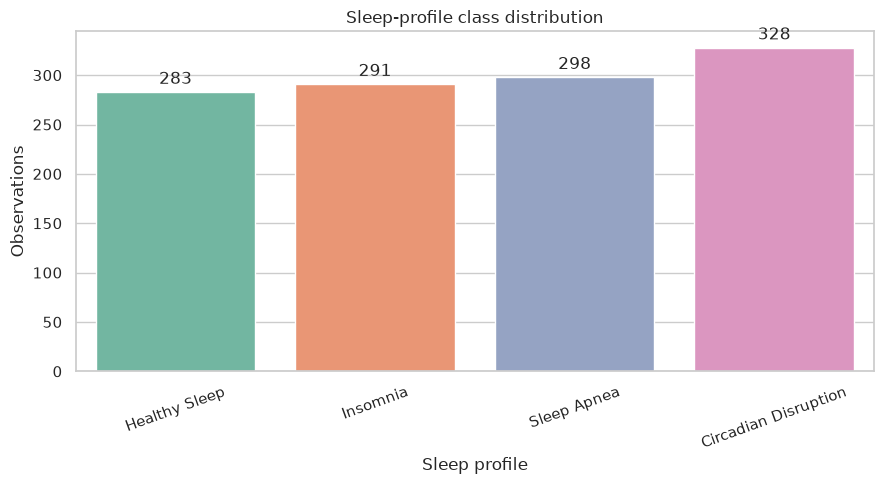

In [5]:
class_summary = (
    eda_df.groupby([TARGET_COLUMN, "label_name"], observed=True)
    .size()
    .rename("count")
    .reset_index()
)
class_summary["percentage"] = 100 * class_summary["count"] / len(eda_df)
class_summary["label_name"] = pd.Categorical(
    class_summary["label_name"], categories=LABEL_ORDER, ordered=True
)
class_summary = class_summary.sort_values("label_name")
class_summary.to_csv(TABLES_DIR / "class_summary.csv", index=False)

display(class_summary)

fig, ax = plt.subplots(figsize=(9, 5))
sns.countplot(
    data=eda_df,
    x="label_name",
    hue="label_name",
    order=LABEL_ORDER,
    palette=CLASS_PALETTE,
    legend=False,
    ax=ax,
)
ax.set(title="Sleep-profile class distribution", xlabel="Sleep profile", ylabel="Observations")
ax.tick_params(axis="x", rotation=20)
for container in ax.containers:
    ax.bar_label(container, fmt="%d", padding=3)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "01_class_distribution.png", dpi=180, bbox_inches="tight")
plt.show()


## 6. Missingness by class

Missingness should be checked **within classes**. A variable can appear nearly complete overall while missing disproportionately in one group.

This synthetic dataset is complete after preprocessing, but the code is written to remain useful if later versions contain missing values.


In [6]:
missing_records = []
for label_name in LABEL_ORDER:
    subset = eda_df.loc[eda_df["label_name"] == label_name]
    for feature in FEATURE_COLUMNS:
        missing_count = int(subset[feature].isna().sum())
        missing_records.append(
            {
                "label_name": label_name,
                "feature": feature,
                "missing_count": missing_count,
                "missing_percentage": 100 * missing_count / len(subset),
            }
        )

missingness_by_class = pd.DataFrame(missing_records)
missingness_by_class.to_csv(TABLES_DIR / "missingness_by_class.csv", index=False)

if missingness_by_class["missing_count"].sum() == 0:
    print("No missing values remain in any feature or class.")
else:
    matrix = missingness_by_class.pivot(
        index="feature", columns="label_name", values="missing_percentage"
    )[LABEL_ORDER]
    fig, ax = plt.subplots(figsize=(9, 10))
    sns.heatmap(
        matrix,
        annot=True,
        fmt=".1f",
        cmap=PASTEL_SEQUENTIAL_CMAP,
        cbar_kws={"label": "Missing values (%)"},
        ax=ax,
    )
    ax.set(title="Missingness within each class", xlabel="Sleep profile", ylabel="Feature")
    fig.tight_layout()
    fig.savefig(FIGURES_DIR / "02_missingness_by_class.png", dpi=180, bbox_inches="tight")
    plt.show()


No missing values remain in any feature or class.


# Part II — Univariate analysis across multiple classes

## 7. Numerical summaries by class

A single global mean or median can hide class-specific structure. Each numerical feature is therefore summarized separately for every sleep profile using both center and spread statistics.


In [7]:
summary_records = []
for feature in NUMERICAL_COLUMNS:
    for label_name in LABEL_ORDER:
        values = eda_df.loc[eda_df["label_name"] == label_name, feature].dropna()
        q1 = values.quantile(0.25)
        q3 = values.quantile(0.75)
        summary_records.append(
            {
                "feature": feature,
                "label_name": label_name,
                "n": len(values),
                "mean": values.mean(),
                "std": values.std(ddof=1),
                "median": values.median(),
                "q1": q1,
                "q3": q3,
                "iqr": q3 - q1,
                "min": values.min(),
                "max": values.max(),
            }
        )

numerical_summary_by_class = pd.DataFrame(summary_records)
numerical_summary_by_class.to_csv(TABLES_DIR / "numerical_summary_by_class.csv", index=False)
display(numerical_summary_by_class.head(12))


,feature,label_name,n,mean,std,median,q1,q3,iqr,min,max
0,age,Healthy Sleep,283,46.088339,14.737032,46.00,36.000,57.000,21.000,18.0,82.0
1,age,Insomnia,291,45.247423,16.111913,44.00,33.000,57.000,24.000,18.0,82.0
2,age,Sleep Apnea,298,49.043624,14.587993,49.00,38.250,58.000,19.750,18.0,82.0
3,age,Circadian Disruption,328,41.182927,14.374738,42.00,30.000,51.000,21.000,18.0,78.0
4,height_cm,Healthy Sleep,283,169.992933,9.291952,169.10,163.000,177.200,14.200,148.0,191.5
5,height_cm,Insomnia,291,170.476289,9.128913,170.30,164.100,177.150,13.050,145.0,200.0
6,height_cm,Sleep Apnea,298,170.690940,9.870953,170.60,163.250,179.025,15.775,145.0,194.8
7,height_cm,Circadian Disruption,328,170.436890,9.255976,170.05,164.175,176.950,12.775,145.7,193.9
8,weight_kg,Healthy Sleep,283,78.062898,16.512033,77.90,65.350,89.300,23.950,44.0,125.5
9,weight_kg,Insomnia,291,77.118213,16.824563,75.30,64.650,86.950,22.300,40.9,144.3


## 8. Numerical distributions across classes

For multiclass EDA, a violin/box-style comparison is often more readable than overlaying four dense histograms. Each panel uses its own y-axis scale and shows the same four classes.

The objective is not to decide significance from a plot. The plot helps identify differences in location, dispersion, skewness, overlap, and possible tails that the statistical tests will later quantify.


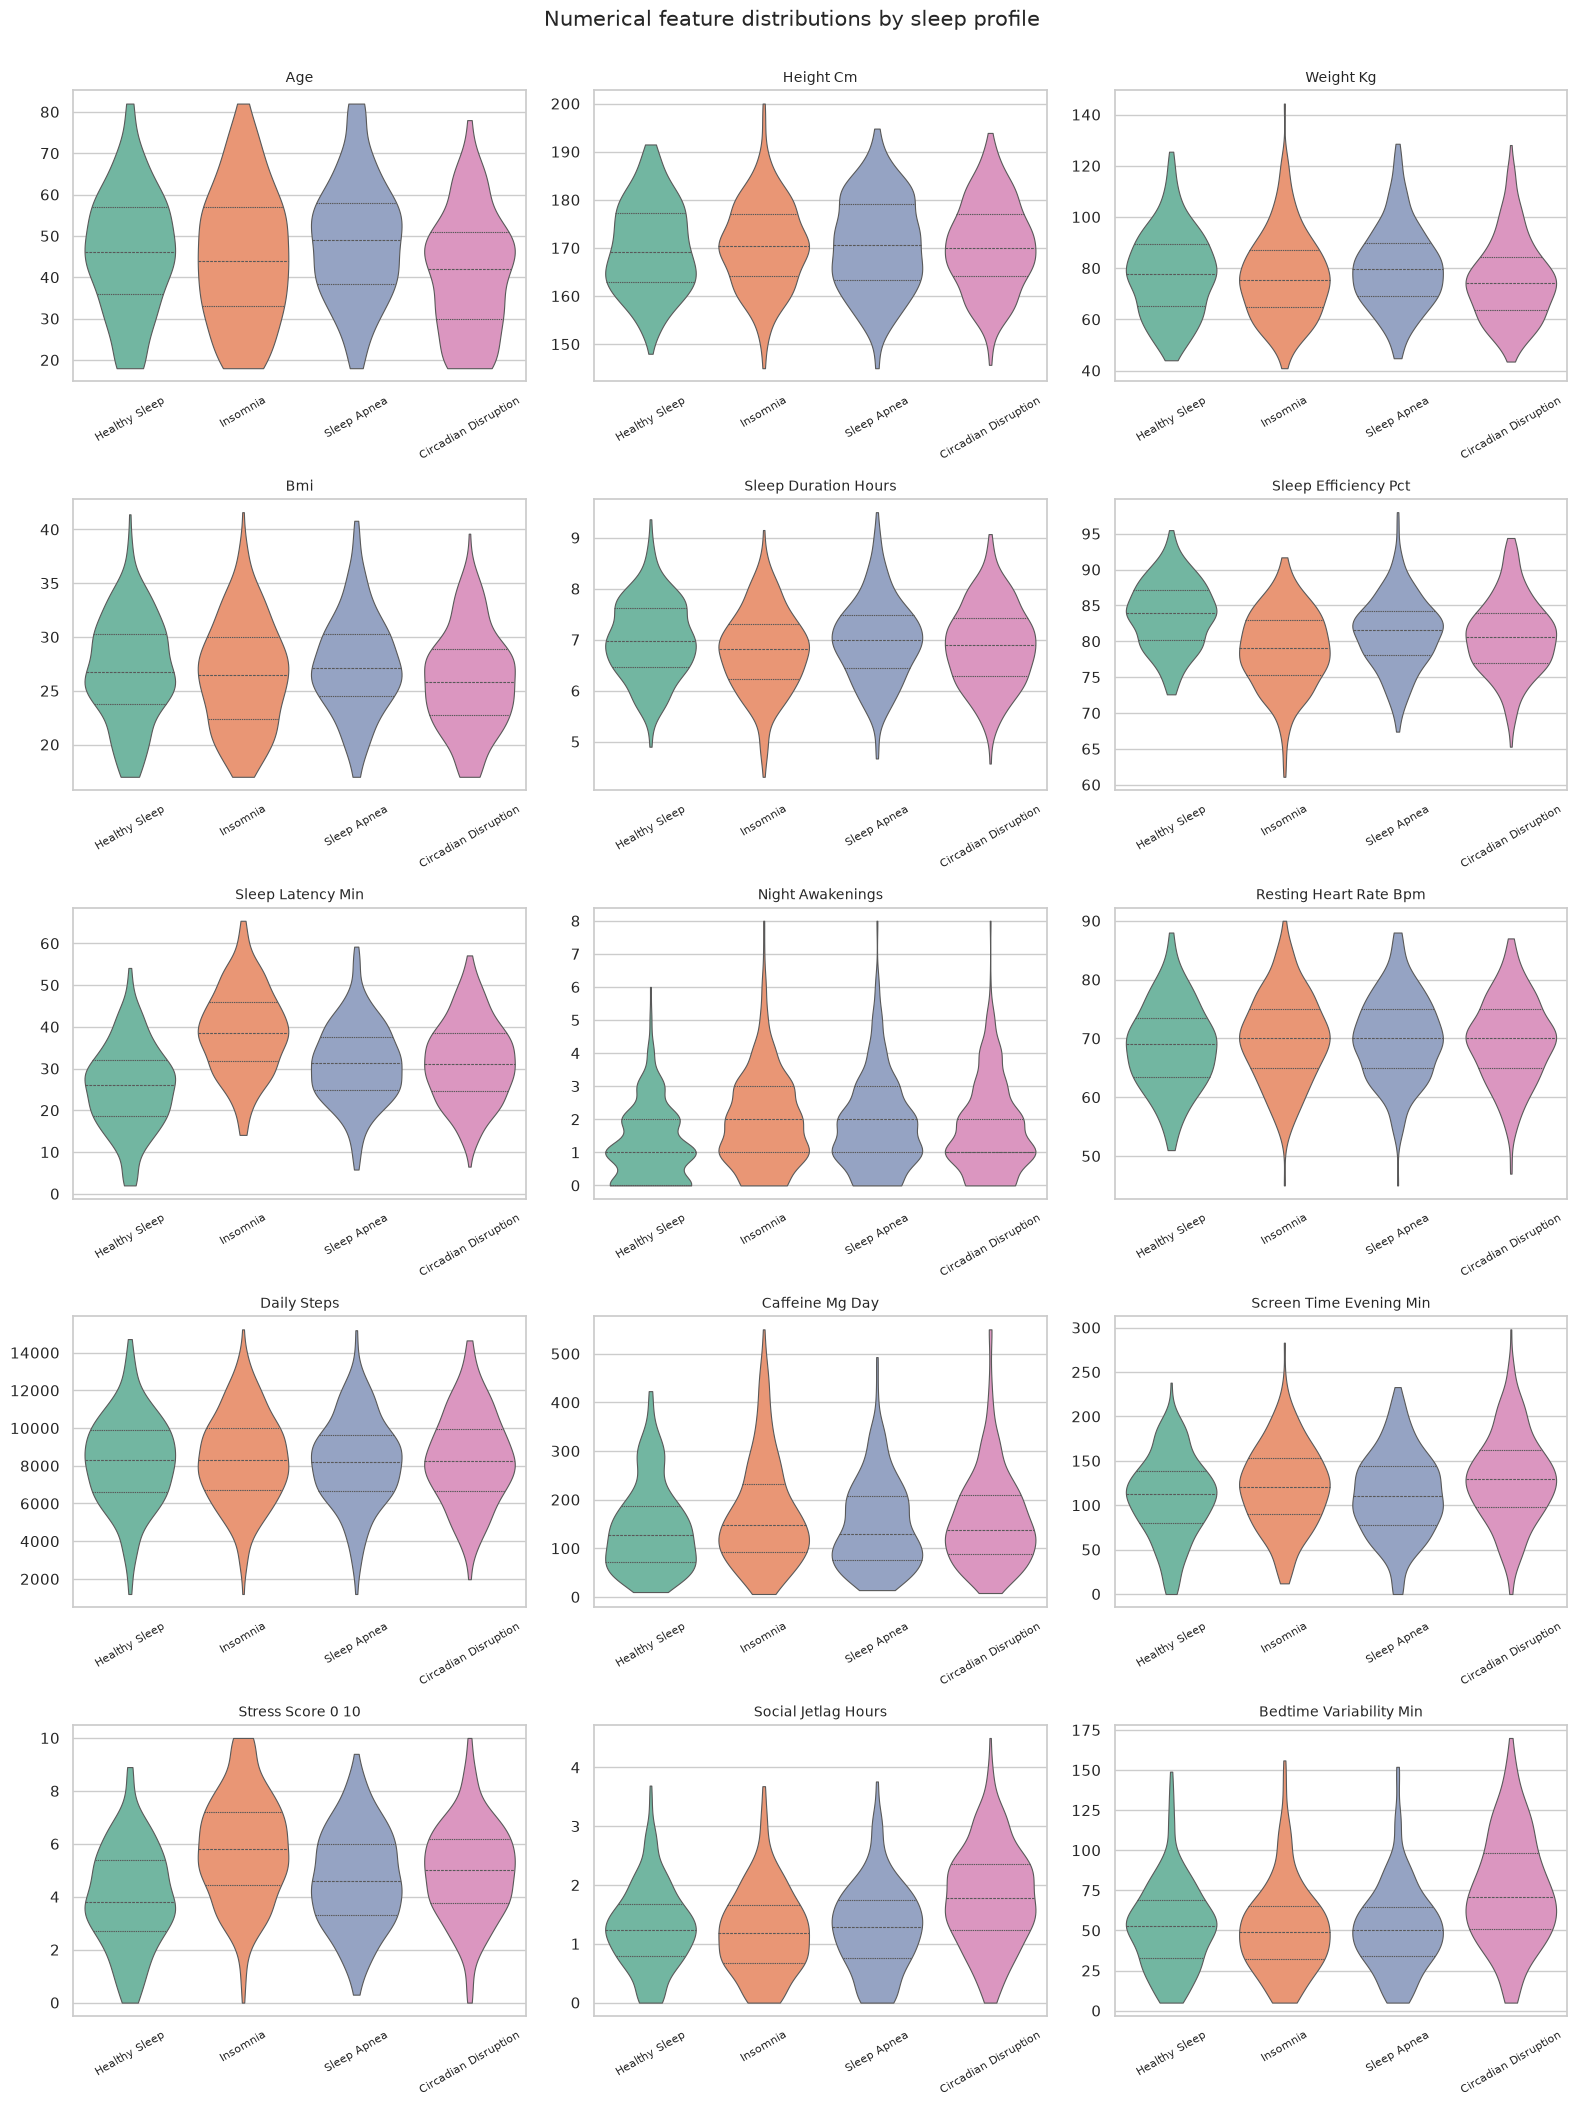

In [8]:
ncols = 3
nrows = int(np.ceil(len(NUMERICAL_COLUMNS) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(16, 4.2 * nrows))
axes = np.atleast_1d(axes).ravel()

for ax, feature in zip(axes, NUMERICAL_COLUMNS):
    sns.violinplot(
        data=eda_df,
        x="label_name",
        y=feature,
        hue="label_name",
        order=LABEL_ORDER,
        hue_order=LABEL_ORDER,
        palette=CLASS_PALETTE,
        inner="quartile",
        cut=0,
        linewidth=0.8,
        legend=False,
        ax=ax,
    )
    ax.set_title(feature.replace("_", " ").title(), fontsize=10)
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.tick_params(axis="x", rotation=30, labelsize=8)

for ax in axes[len(NUMERICAL_COLUMNS):]:
    ax.remove()

fig.suptitle("Numerical feature distributions by sleep profile", y=1.002, fontsize=15)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "03_numerical_distributions_by_class.png", dpi=180, bbox_inches="tight")
plt.show()


## 9. Binary categorical prevalence within each class

The categorical predictors are binary indicators. Their mean within a class is therefore the fraction of observations for which that characteristic is present.

For each feature we calculate:

`P(feature = 1 | sleep profile) × 100`

Consequently, percentages across a row **are not expected to sum to 100%**. Each column uses a different class-specific denominator. The table asks, for example, “what percentage of participants in the insomnia group have anxiety history?”, not “how are participants with anxiety history distributed among classes?”.


Sleep-profile class prevalence (%),Healthy Sleep,Insomnia,Sleep Apnea,Circadian Disruption
Binary feature,,,,
sex_female,55.5,52.9,48.3,53.0
shift_worker,3.9,7.6,4.7,31.4
regular_exercise,64.3,60.5,58.1,62.2
evening_alcohol,18.7,21.6,20.8,24.1
loud_snoring,1.8,4.8,8.1,5.5
anxiety_history,14.1,30.2,22.5,15.9


Percentages are calculated within each class; rows are not expected to sum to 100%.


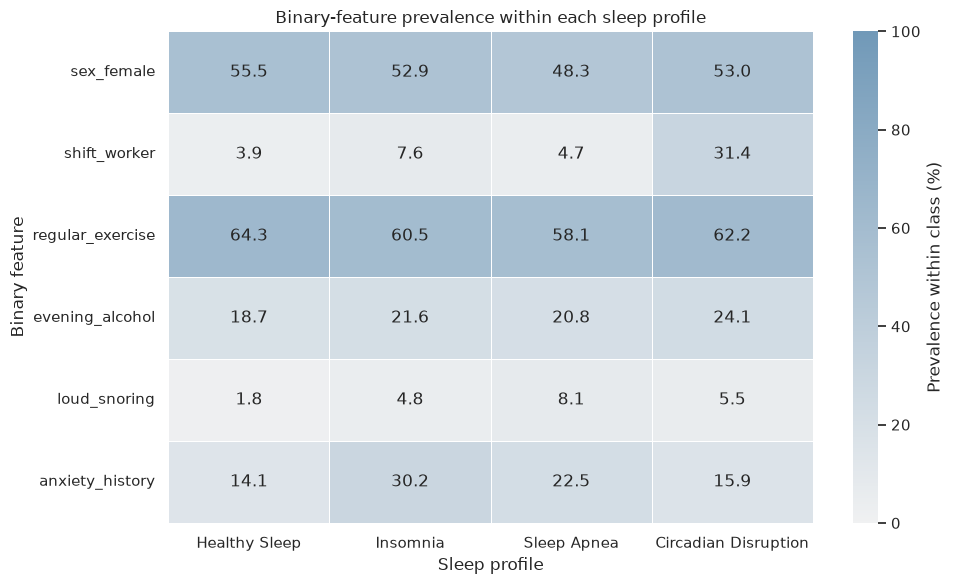

In [9]:
prevalence = (
    eda_df.groupby("label_name", observed=True)[CATEGORICAL_COLUMNS]
    .mean()
    .mul(100)
    .reindex(LABEL_ORDER)
    .T
)
prevalence.columns.name = "Sleep-profile class prevalence (%)"
prevalence.index.name = "Binary feature"
prevalence.to_csv(TABLES_DIR / "categorical_prevalence_by_class.csv")

display(prevalence.round(1))
print("Percentages are calculated within each class; rows are not expected to sum to 100%.")

fig, ax = plt.subplots(figsize=(10, 6))
sns.heatmap(
    prevalence,
    annot=True,
    fmt=".1f",
    cmap=PASTEL_SEQUENTIAL_CMAP,
    vmin=0,
    vmax=100,
    linewidths=0.5,
    cbar_kws={"label": "Prevalence within class (%)"},
    ax=ax,
)
ax.set(title="Binary-feature prevalence within each sleep profile", xlabel="Sleep profile", ylabel="Binary feature")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "04_categorical_prevalence_by_class.png", dpi=180, bbox_inches="tight")
plt.show()


# Part III — Outliers and group-aware diagnostics

## 10. IQR outliers within each class

Outliers are flagged separately within each class using the conventional `Q1 − 1.5×IQR` and `Q3 + 1.5×IQR` rule.

This is a **diagnostic flag**, not an automatic deletion rule. A value can be unusual and still be valid. Class-wise thresholds are used here because a value that is extreme for one group may be typical for another.


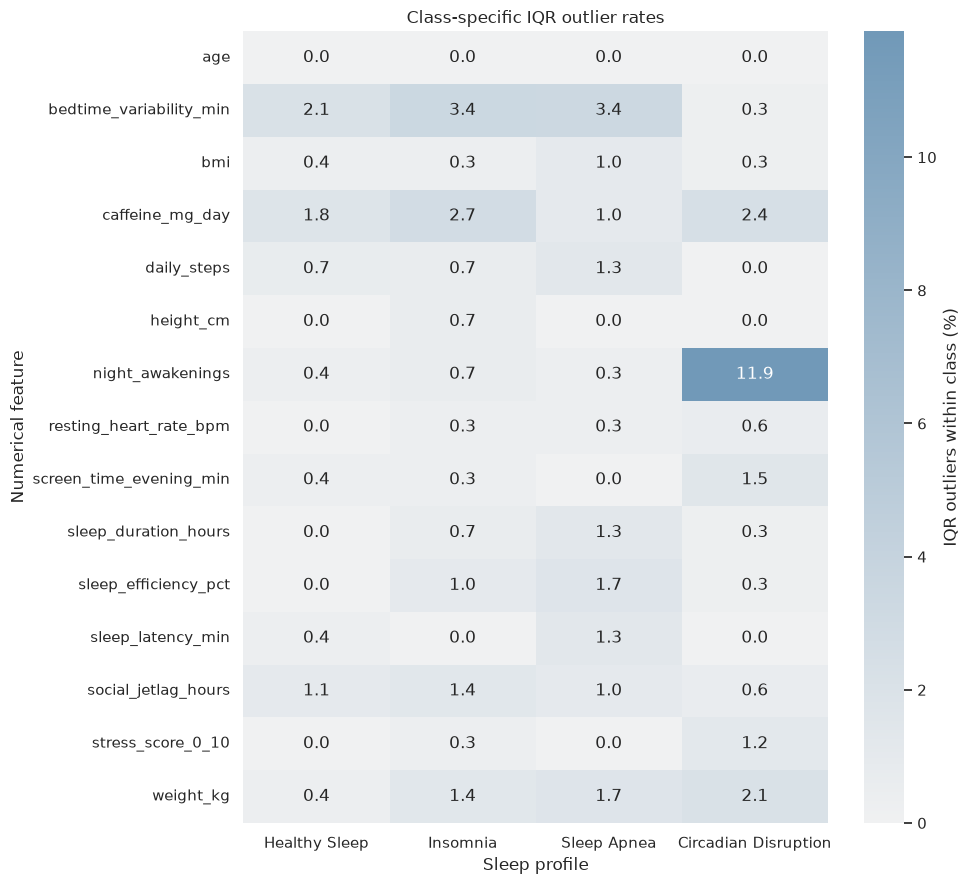

In [10]:
outlier_records = []
for label_name in LABEL_ORDER:
    subset = eda_df.loc[eda_df["label_name"] == label_name]
    for feature in NUMERICAL_COLUMNS:
        values = subset[feature].dropna()
        q1, q3 = values.quantile([0.25, 0.75])
        iqr = q3 - q1
        lower = q1 - 1.5 * iqr
        upper = q3 + 1.5 * iqr
        count = int(((values < lower) | (values > upper)).sum())
        outlier_records.append(
            {
                "label_name": label_name,
                "feature": feature,
                "lower_bound": lower,
                "upper_bound": upper,
                "outlier_count": count,
                "outlier_percentage": 100 * count / len(values),
            }
        )

outliers_by_class = pd.DataFrame(outlier_records)
outliers_by_class.to_csv(TABLES_DIR / "outliers_by_class.csv", index=False)

outlier_matrix = outliers_by_class.pivot(
    index="feature", columns="label_name", values="outlier_percentage"
)[LABEL_ORDER]

fig, ax = plt.subplots(figsize=(10, 9))
sns.heatmap(
    outlier_matrix,
    annot=True,
    fmt=".1f",
    cmap=PASTEL_SEQUENTIAL_CMAP,
    cbar_kws={"label": "IQR outliers within class (%)"},
    ax=ax,
)
ax.set(title="Class-specific IQR outlier rates", xlabel="Sleep profile", ylabel="Numerical feature")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "05_outlier_rates_by_class.png", dpi=180, bbox_inches="tight")
plt.show()


# Part IV — Statistical comparison of numerical variables

## 11. Omnibus tests and effect sizes

With four classes, repeatedly performing binary tests first would inflate the number of comparisons and obscure the multiclass question. We begin with **omnibus tests**:

- one-way ANOVA asks whether group means differ somewhere across the classes;
- Kruskal–Wallis asks whether the distributions/ranks differ somewhere across the classes;
- Levene's test describes evidence for unequal variances.

A significant omnibus test does **not** identify which classes differ. Pairwise follow-up analysis comes later.

We also calculate two multiclass effect sizes:

- `eta_squared`, the proportion of total variance associated with between-class differences;
- `epsilon_squared`, a rank-based effect size associated with the Kruskal–Wallis statistic.

Because many features are tested, p-values are corrected using Benjamini–Hochberg false-discovery-rate control.


In [11]:
def eta_squared(values: pd.Series, groups: pd.Series) -> float:
    frame = pd.DataFrame({"value": values, "group": groups}).dropna()
    grand_mean = frame["value"].mean()
    ss_total = ((frame["value"] - grand_mean) ** 2).sum()
    ss_between = sum(
        len(g) * (g["value"].mean() - grand_mean) ** 2
        for _, g in frame.groupby("group", observed=True)
    )
    return float(ss_between / ss_total) if ss_total > 0 else np.nan


omnibus_records = []
for feature in NUMERICAL_COLUMNS:
    groups = [
        eda_df.loc[eda_df["label_name"] == label_name, feature].dropna().to_numpy()
        for label_name in LABEL_ORDER
    ]

    anova = stats.f_oneway(*groups)
    kruskal = stats.kruskal(*groups)
    levene = stats.levene(*groups, center="median")

    n_total = sum(len(g) for g in groups)
    k = len(groups)
    epsilon2 = max(0.0, (kruskal.statistic - k + 1) / (n_total - k))

    omnibus_records.append(
        {
            "feature": feature,
            "anova_F": anova.statistic,
            "anova_p": anova.pvalue,
            "kruskal_H": kruskal.statistic,
            "kruskal_p": kruskal.pvalue,
            "levene_statistic": levene.statistic,
            "levene_p": levene.pvalue,
            "eta_squared": eta_squared(eda_df[feature], eda_df["label_name"]),
            "epsilon_squared": epsilon2,
        }
    )

numerical_omnibus = pd.DataFrame(omnibus_records)
numerical_omnibus["anova_q_fdr"] = multipletests(
    numerical_omnibus["anova_p"], method="fdr_bh"
)[1]
numerical_omnibus["kruskal_q_fdr"] = multipletests(
    numerical_omnibus["kruskal_p"], method="fdr_bh"
)[1]
numerical_omnibus = numerical_omnibus.sort_values(
    "epsilon_squared", ascending=False
).reset_index(drop=True)

numerical_omnibus.to_csv(TABLES_DIR / "numerical_multiclass_tests.csv", index=False)
display(numerical_omnibus.round(4))


,feature,anova_F,anova_p,kruskal_H,kruskal_p,levene_statistic,levene_p,eta_squared,epsilon_squared,anova_q_fdr,kruskal_q_fdr
0,sleep_latency_min,88.7749,0.0000,206.0828,0.0000,0.5688,0.6357,0.1821,0.1698,0.0000,0.0000
1,sleep_efficiency_pct,44.4479,0.0000,117.5384,0.0000,1.8421,0.1377,0.1003,0.0958,0.0000,0.0000
2,stress_score_0_10,47.9229,0.0000,117.0532,0.0000,1.6901,0.1673,0.1073,0.0954,0.0000,0.0000
3,bedtime_variability_min,48.3043,0.0000,114.9249,0.0000,10.5205,0.0000,0.1081,0.0936,0.0000,0.0000
4,social_jetlag_hours,41.2286,0.0000,103.4097,0.0000,5.3393,0.0012,0.0937,0.0840,0.0000,0.0000
5,night_awakenings,14.5969,0.0000,43.4561,0.0000,4.3693,0.0045,0.0353,0.0338,0.0000,0.0000
6,age,14.7835,0.0000,39.3869,0.0000,2.4396,0.0629,0.0358,0.0304,0.0000,0.0000
7,screen_time_evening_min,13.2954,0.0000,33.2273,0.0000,0.5373,0.6568,0.0323,0.0253,0.0000,0.0000
8,bmi,5.6682,0.0007,16.3611,0.0010,1.8632,0.1340,0.0140,0.0112,0.0012,0.0016
9,weight_kg,4.3438,0.0047,15.0271,0.0018,0.5202,0.6684,0.0108,0.0101,0.0059,0.0027


## 12. Rank numerical features by multiclass effect size

A small p-value can arise from a small effect in a sufficiently large sample. Ranking by effect size helps distinguish **statistical evidence** from **magnitude of separation**.

The bar chart below uses `epsilon_squared`, while the exported table preserves both parametric and rank-based statistics.


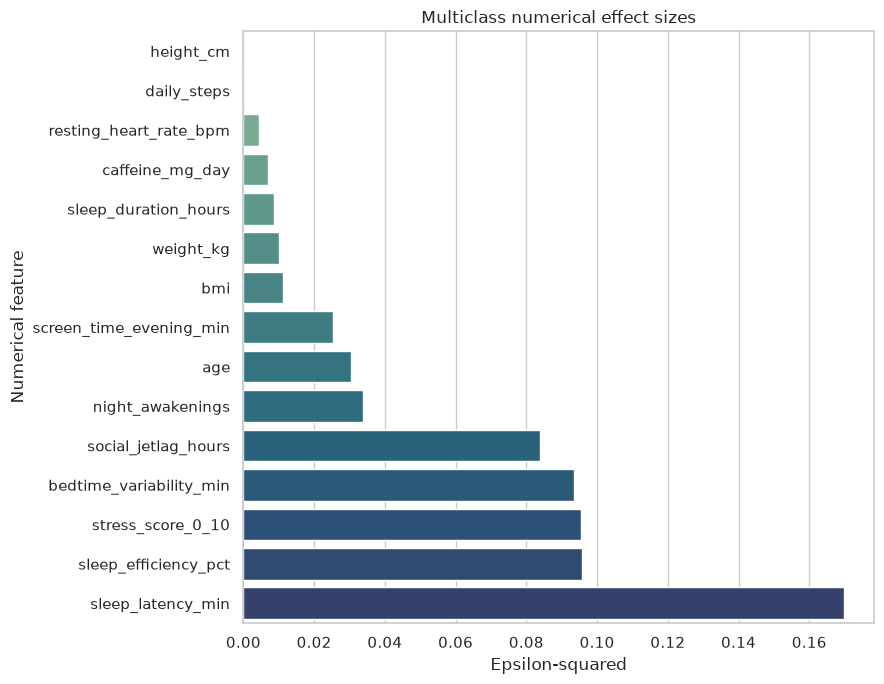

In [12]:
plot_df = numerical_omnibus.sort_values("epsilon_squared", ascending=True)
fig, ax = plt.subplots(figsize=(9, 7))
sns.barplot(
    data=plot_df,
    x="epsilon_squared",
    y="feature",
    hue="feature",
    palette=sns.color_palette("crest", n_colors=len(plot_df)),
    legend=False,
    ax=ax,
)
ax.set(title="Multiclass numerical effect sizes", xlabel="Epsilon-squared", ylabel="Numerical feature")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "06_numerical_effect_sizes.png", dpi=180, bbox_inches="tight")
plt.show()


## 13. Pairwise follow-up for the strongest numerical variables

An omnibus result answers “is there evidence of a difference somewhere?”. It does not answer “which groups differ?”.

For the five strongest variables by rank-based effect size, we perform all pairwise Mann–Whitney comparisons. The rank-biserial form of Cliff's delta is derived from the U statistic to quantify direction and magnitude.

All pairwise p-values are corrected together using FDR. This section is intentionally a **follow-up**, not the starting point of the multiclass analysis.


In [13]:
top_pairwise_features = numerical_omnibus.head(5)["feature"].tolist()
pairwise_records = []

for feature in top_pairwise_features:
    for class_a, class_b in combinations(LABEL_ORDER, 2):
        a = eda_df.loc[eda_df["label_name"] == class_a, feature].dropna().to_numpy()
        b = eda_df.loc[eda_df["label_name"] == class_b, feature].dropna().to_numpy()
        mw = stats.mannwhitneyu(a, b, alternative="two-sided")
        cliff_delta = 2 * mw.statistic / (len(a) * len(b)) - 1
        pairwise_records.append(
            {
                "feature": feature,
                "class_a": class_a,
                "class_b": class_b,
                "median_a": np.median(a),
                "median_b": np.median(b),
                "mannwhitney_U": mw.statistic,
                "p_value": mw.pvalue,
                "cliffs_delta_a_vs_b": cliff_delta,
            }
        )

pairwise_followup = pd.DataFrame(pairwise_records)
pairwise_followup["q_fdr"] = multipletests(pairwise_followup["p_value"], method="fdr_bh")[1]
pairwise_followup["significant_fdr_0.05"] = pairwise_followup["q_fdr"] < 0.05
pairwise_followup.to_csv(TABLES_DIR / "pairwise_followup_top_numerical_features.csv", index=False)

display(pairwise_followup.round(4))


,feature,class_a,class_b,median_a,median_b,mannwhitney_U,p_value,cliffs_delta_a_vs_b,q_fdr,significant_fdr_0.05
0,sleep_latency_min,Healthy Sleep,Insomnia,26.00,38.50,14598.5,0.0000,-0.6455,0.0000,True
1,sleep_latency_min,Healthy Sleep,Sleep Apnea,26.00,31.30,29094.0,0.0000,-0.3100,0.0000,True
2,sleep_latency_min,Healthy Sleep,Circadian Disruption,26.00,31.20,30949.0,0.0000,-0.3332,0.0000,True
3,sleep_latency_min,Insomnia,Sleep Apnea,38.50,31.30,61790.5,0.0000,0.4251,0.0000,True
4,sleep_latency_min,Insomnia,Circadian Disruption,38.50,31.20,66199.5,0.0000,0.3871,0.0000,True
5,sleep_latency_min,Sleep Apnea,Circadian Disruption,31.30,31.20,47318.5,0.4920,-0.0318,0.5466,False
6,sleep_efficiency_pct,Healthy Sleep,Insomnia,84.00,79.10,61667.5,0.0000,0.4976,0.0000,True
7,sleep_efficiency_pct,Healthy Sleep,Sleep Apnea,84.00,81.50,55091.5,0.0000,0.3065,0.0000,True
8,sleep_efficiency_pct,Healthy Sleep,Circadian Disruption,84.00,80.65,62462.0,0.0000,0.3458,0.0000,True
9,sleep_efficiency_pct,Insomnia,Sleep Apnea,79.10,81.50,33476.0,0.0000,-0.2279,0.0000,True


# Part V — Categorical features and multiclass association

## 14. Chi-square tests and Cramér's V

For each binary categorical predictor, a contingency table is formed against the four-class target.

- the chi-square test evaluates evidence of dependence;
- Cramér's V quantifies association strength and remains interpretable for a table larger than 2×2;
- FDR correction accounts for testing multiple categorical variables.

The test asks whether class composition and the categorical feature are associated. It does not establish causality.


,feature,chi2,dof,p_value,min_expected_count,cramers_v,q_fdr
0,shift_worker,149.4219,3,0.0000,35.3750,0.3529,0.0000
1,anxiety_history,28.9493,3,0.0000,58.2508,0.1553,0.0000
2,loud_snoring,12.0569,3,0.0072,14.3858,0.1002,0.0144
3,sex_female,3.1480,3,0.3694,134.6608,0.0512,0.4582
4,evening_alcohol,2.6792,3,0.4438,60.6092,0.0473,0.4582
5,regular_exercise,2.5958,3,0.4582,109.6625,0.0465,0.4582


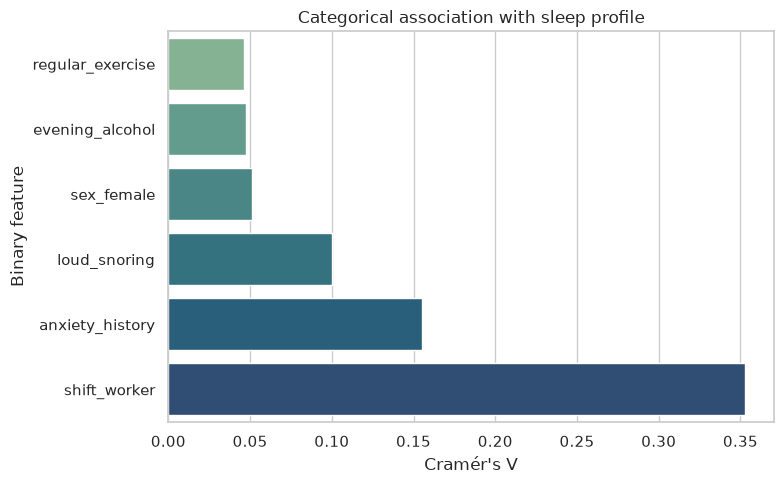

In [14]:
categorical_records = []
for feature in CATEGORICAL_COLUMNS:
    contingency = pd.crosstab(eda_df[TARGET_COLUMN], eda_df[feature])
    chi2, p_value, dof, expected = stats.chi2_contingency(contingency)
    n = contingency.to_numpy().sum()
    min_dim = min(contingency.shape) - 1
    cramers_v = np.sqrt(chi2 / (n * min_dim)) if min_dim > 0 else np.nan

    categorical_records.append(
        {
            "feature": feature,
            "chi2": chi2,
            "dof": dof,
            "p_value": p_value,
            "min_expected_count": expected.min(),
            "cramers_v": cramers_v,
        }
    )

categorical_tests = pd.DataFrame(categorical_records)
categorical_tests["q_fdr"] = multipletests(categorical_tests["p_value"], method="fdr_bh")[1]
categorical_tests = categorical_tests.sort_values("cramers_v", ascending=False).reset_index(drop=True)
categorical_tests.to_csv(TABLES_DIR / "categorical_multiclass_tests.csv", index=False)

display(categorical_tests.round(4))

fig, ax = plt.subplots(figsize=(8, 5))
plot_df = categorical_tests.sort_values("cramers_v", ascending=True)
sns.barplot(
    data=plot_df,
    x="cramers_v",
    y="feature",
    hue="feature",
    palette=sns.color_palette("crest", n_colors=len(plot_df)),
    legend=False,
    ax=ax,
)
ax.set(title="Categorical association with sleep profile", xlabel="Cramér's V", ylabel="Binary feature")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "07_categorical_effect_sizes.png", dpi=180, bbox_inches="tight")
plt.show()


# Part VI — Bivariate and class-specific dependence structure

## 15. Focused pairplot

A full pairplot of every numerical feature becomes unreadable. Instead, we use the five strongest numerical variables from the omnibus analysis and color observations by sleep profile.

The pairplot is exploratory. Apparent clusters or slopes should be verified with targeted statistics rather than interpreted as proof of separability.


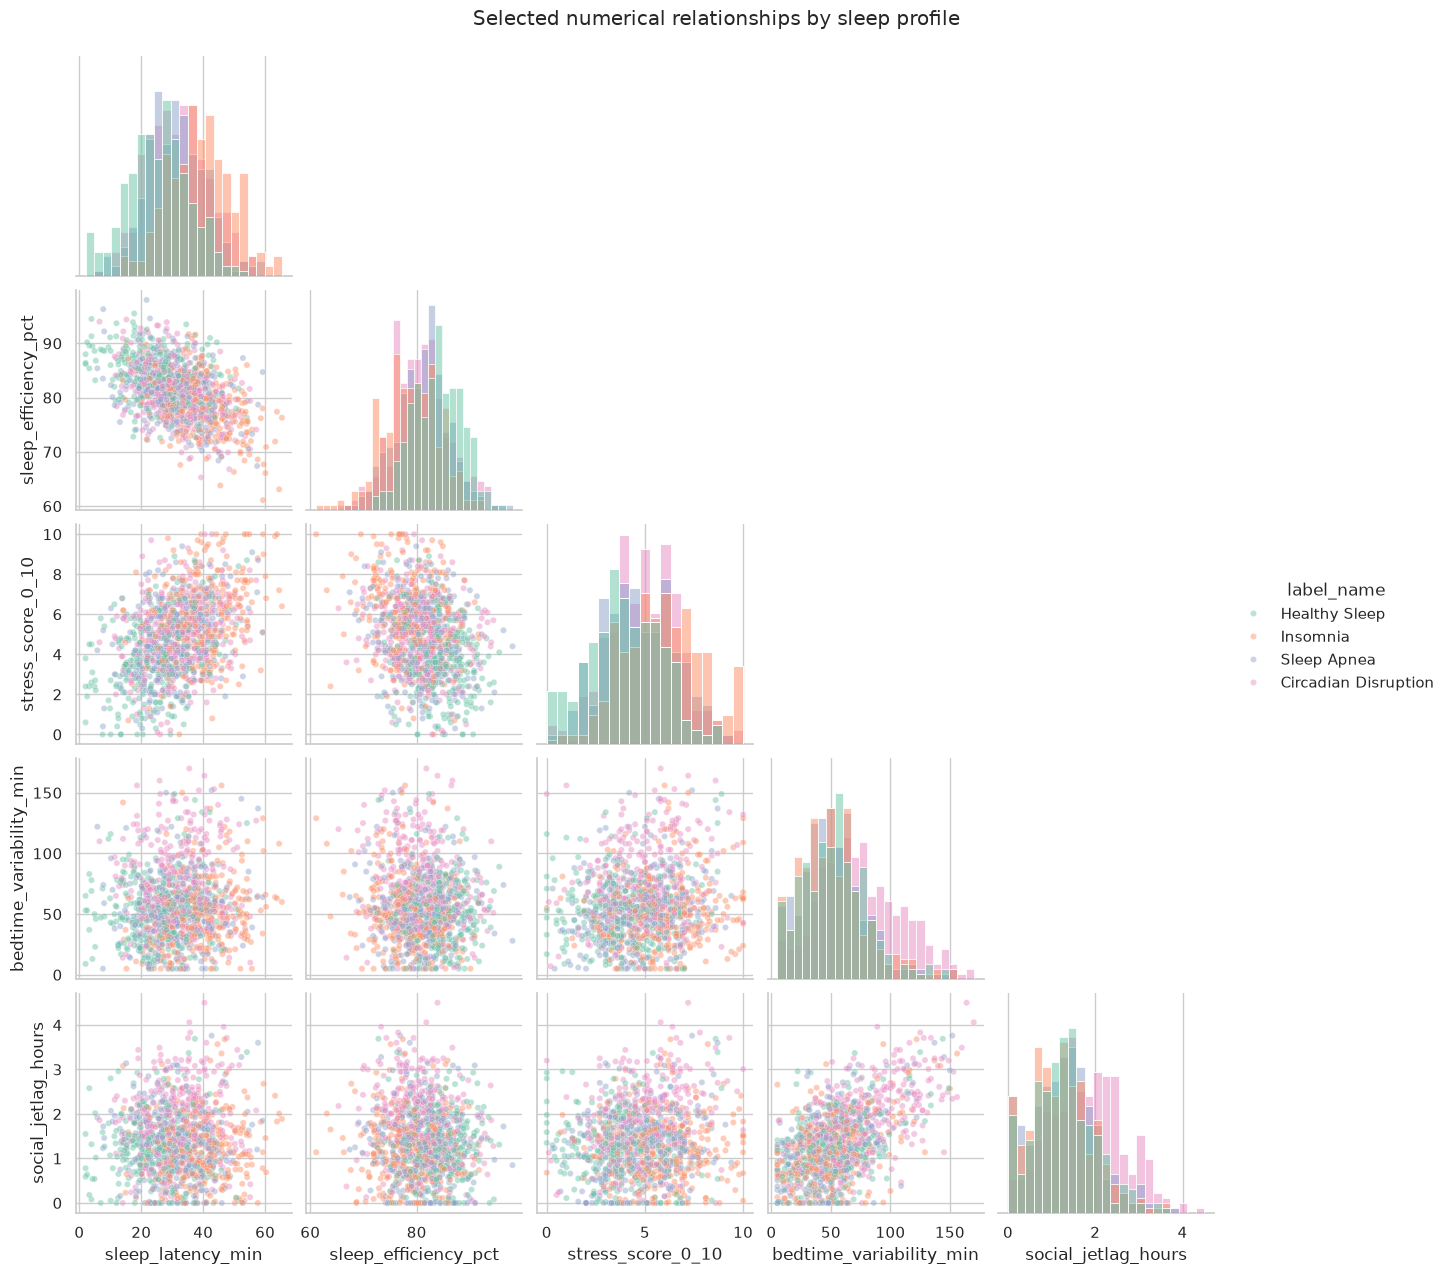

In [15]:
PAIRPLOT_FEATURES = numerical_omnibus.head(5)["feature"].tolist()
pairplot_data = eda_df[PAIRPLOT_FEATURES + ["label_name"]].copy()

pair_grid = sns.pairplot(
    pairplot_data,
    vars=PAIRPLOT_FEATURES,
    hue="label_name",
    hue_order=LABEL_ORDER,
    palette=CLASS_PALETTE,
    corner=True,
    diag_kind="hist",
    plot_kws={"alpha": 0.45, "s": 20},
)
pair_grid.fig.suptitle("Selected numerical relationships by sleep profile", y=1.02)
pair_grid.fig.savefig(FIGURES_DIR / "08_pairplot_selected_features.png", dpi=160, bbox_inches="tight")
plt.show()


## 16. Spearman correlation structure within each class

A global correlation can mix relationships that differ between classes. We therefore estimate Spearman correlations **separately within each sleep profile**.

To keep the figure readable, the heatmaps use the ten numerical variables with the largest multiclass effect sizes. All panels use the same `[-1, 1]` scale so colors are comparable.


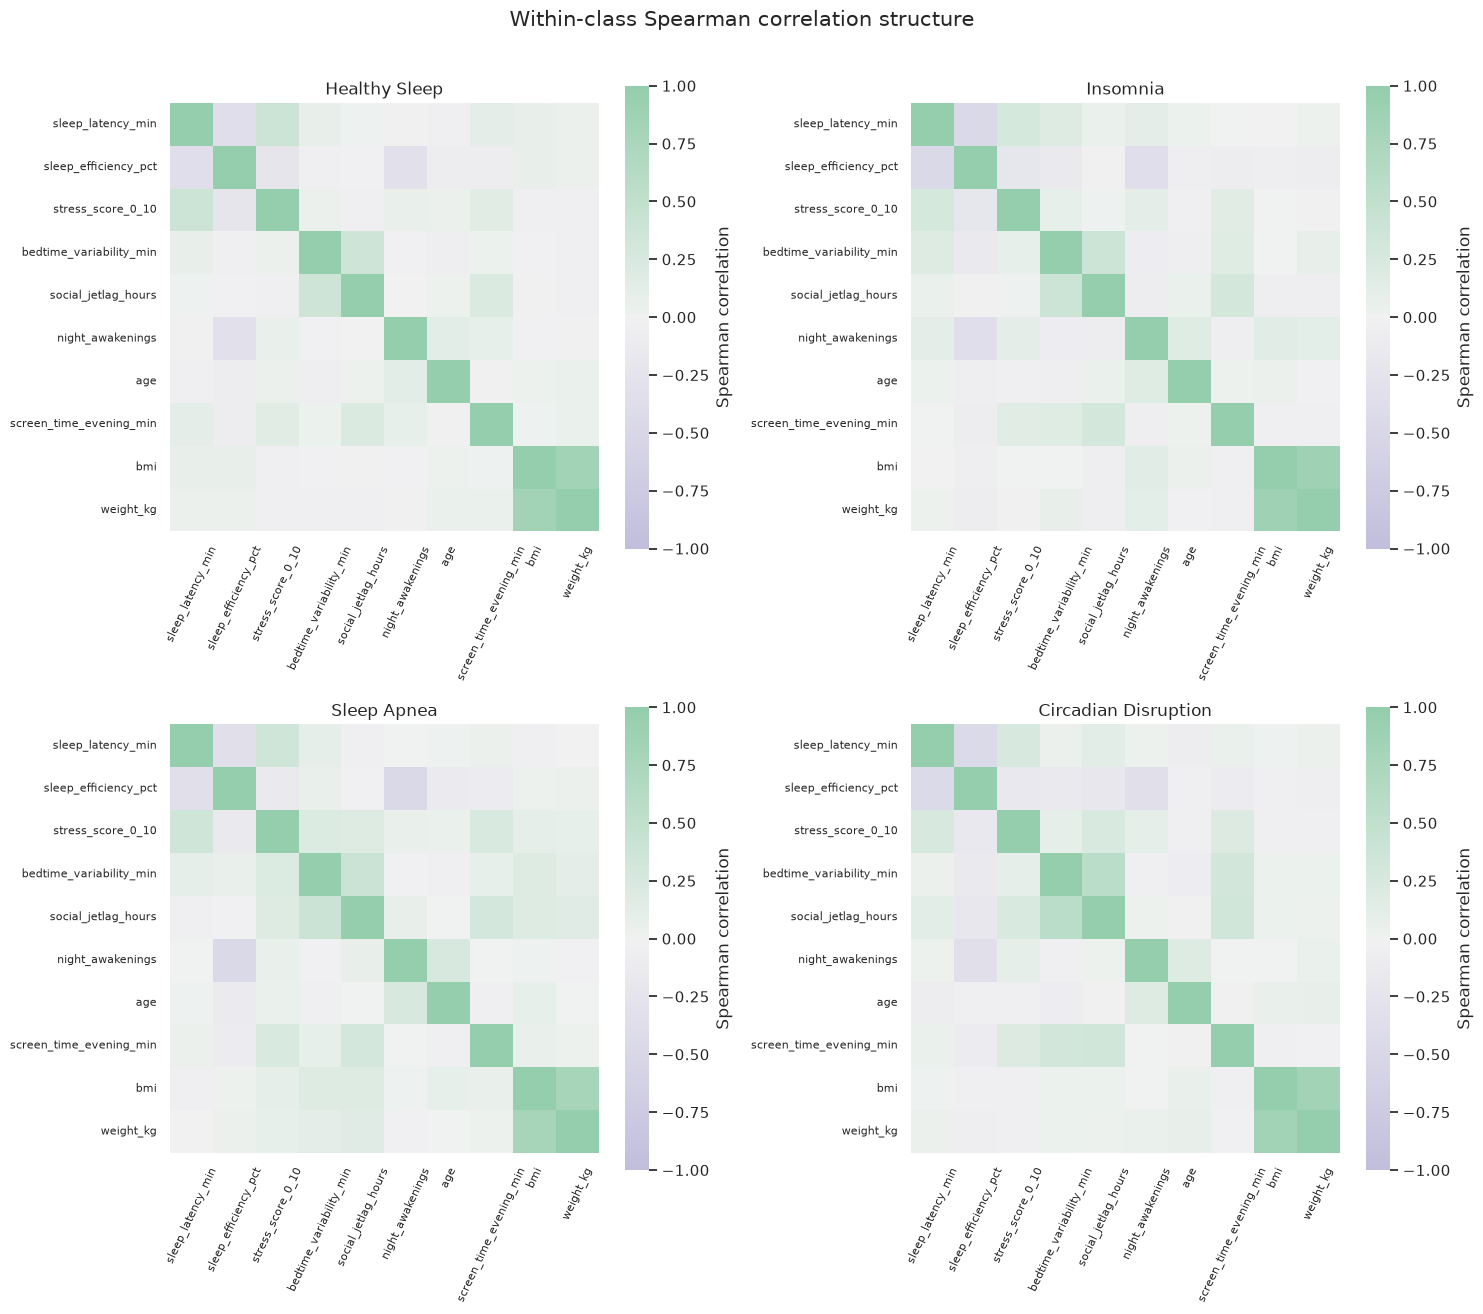

In [16]:
CORRELATION_FEATURES = numerical_omnibus.head(min(10, len(NUMERICAL_COLUMNS)))["feature"].tolist()

ncols = 2
nrows = int(np.ceil(len(LABEL_ORDER) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(15, 6.5 * nrows))
axes = np.atleast_1d(axes).ravel()

for ax, label_name in zip(axes, LABEL_ORDER):
    corr = eda_df.loc[eda_df["label_name"] == label_name, CORRELATION_FEATURES].corr(method="spearman")
    corr.to_csv(TABLES_DIR / f"spearman_{label_name.lower().replace(' ', '_')}.csv")
    sns.heatmap(
        corr,
        vmin=-1,
        vmax=1,
        center=0,
        cmap=PASTEL_DIVERGING_CMAP,
        square=True,
        cbar_kws={"label": "Spearman correlation"},
        ax=ax,
    )
    ax.set_title(label_name)
    ax.tick_params(axis="x", rotation=65, labelsize=8)
    ax.tick_params(axis="y", labelsize=8)

for ax in axes[len(LABEL_ORDER):]:
    ax.remove()

fig.suptitle("Within-class Spearman correlation structure", y=1.01, fontsize=15)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "09_class_specific_correlations.png", dpi=180, bbox_inches="tight")
plt.show()


# Part VII — Multivariable geometry

## 17. Standardize predictors before projection

PCA, t-SNE, and UMAP are sensitive to feature scale. All predictors are standardized before projection.

The target label is **not included** in the input matrix. It is used only after projection to color points. This distinction is essential: coloring a projection by class does not make the projection supervised.


In [17]:
X = eda_df[FEATURE_COLUMNS].astype(float)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Projection matrix shape:", X_scaled.shape)
print("Target included in projection matrix:", TARGET_COLUMN in FEATURE_COLUMNS)


Projection matrix shape: (1200, 21)
Target included in projection matrix: False


## 18. Principal Component Analysis (PCA)

PCA is a **linear unsupervised projection**. It finds orthogonal directions that capture decreasing amounts of predictor variance.

Two complementary outputs are important:

- **scores** describe where observations lie in component space;
- **loadings** describe how original variables contribute to each component.

PCA does not optimize class separation. If classes separate in PCA space, that separation emerges from the predictor variance structure rather than from using the labels to construct the components.


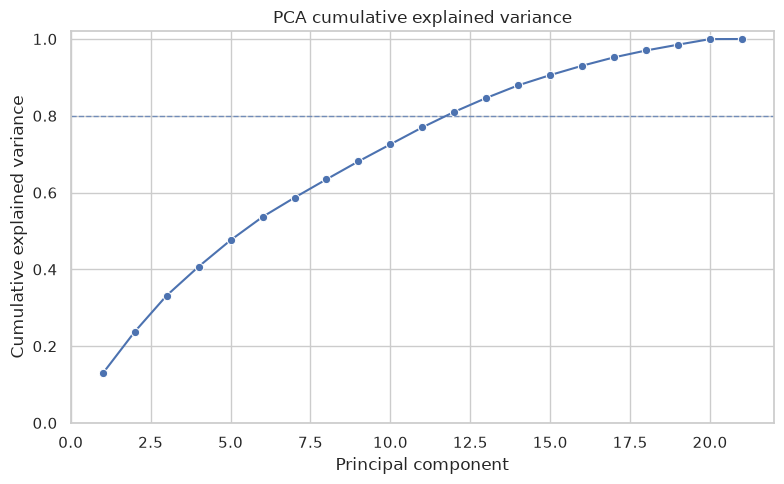

In [18]:
pca_full = PCA().fit(X_scaled)
explained = pd.DataFrame(
    {
        "component": np.arange(1, len(pca_full.explained_variance_ratio_) + 1),
        "explained_variance_ratio": pca_full.explained_variance_ratio_,
        "cumulative_explained_variance": np.cumsum(pca_full.explained_variance_ratio_),
    }
)
explained.to_csv(TABLES_DIR / "pca_explained_variance.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 5))
sns.lineplot(data=explained, x="component", y="cumulative_explained_variance", marker="o", ax=ax)
ax.axhline(0.80, linestyle="--", linewidth=1, alpha=0.7)
ax.set(title="PCA cumulative explained variance", xlabel="Principal component", ylabel="Cumulative explained variance")
ax.set_ylim(0, 1.02)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "10_pca_explained_variance.png", dpi=180, bbox_inches="tight")
plt.show()


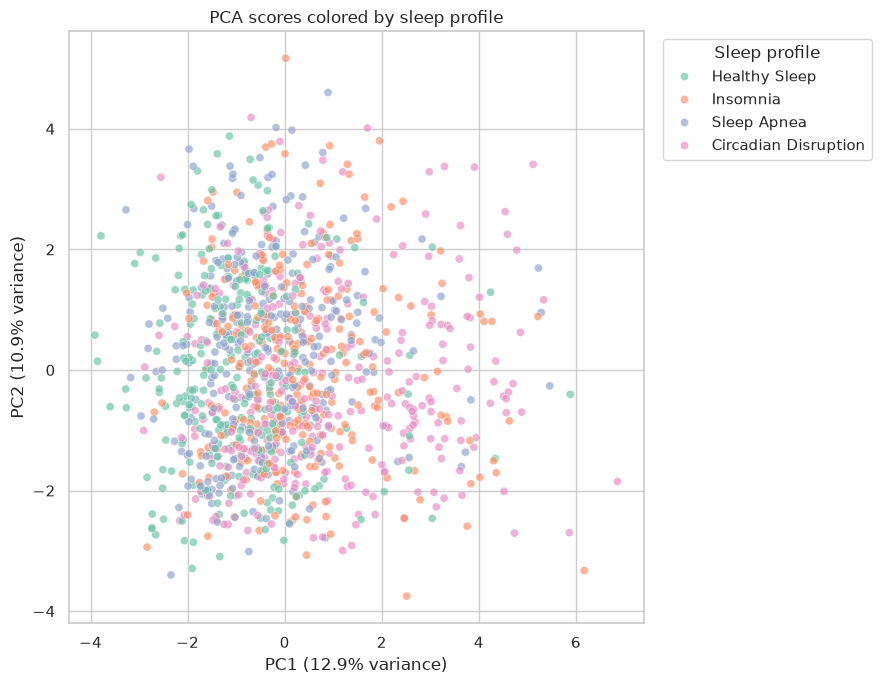

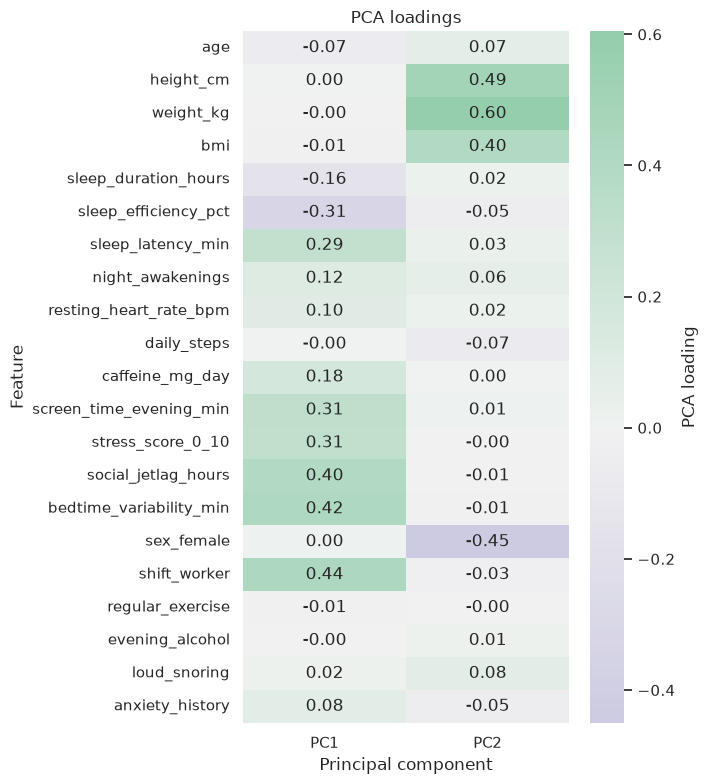

In [19]:
pca_2d = PCA(n_components=2)
X_pca = pca_2d.fit_transform(X_scaled)

pca_scores = pd.DataFrame(X_pca, columns=["PC1", "PC2"])
pca_scores["label_name"] = eda_df["label_name"].to_numpy()
pca_scores.to_csv(TABLES_DIR / "pca_scores.csv", index=False)

loadings = pd.DataFrame(
    pca_2d.components_.T,
    index=FEATURE_COLUMNS,
    columns=["PC1", "PC2"],
)
loadings.to_csv(TABLES_DIR / "pca_loadings.csv")

fig, ax = plt.subplots(figsize=(9, 7))
sns.scatterplot(
    data=pca_scores,
    x="PC1",
    y="PC2",
    hue="label_name",
    hue_order=LABEL_ORDER,
    palette=CLASS_PALETTE,
    alpha=0.65,
    s=35,
    ax=ax,
)
ax.set(
    title="PCA scores colored by sleep profile",
    xlabel=f"PC1 ({100 * pca_2d.explained_variance_ratio_[0]:.1f}% variance)",
    ylabel=f"PC2 ({100 * pca_2d.explained_variance_ratio_[1]:.1f}% variance)",
)
ax.legend(title="Sleep profile", bbox_to_anchor=(1.02, 1), loc="upper left")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "11_pca_scores_by_class.png", dpi=180, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(7, 8))
sns.heatmap(
    loadings,
    annot=True,
    fmt=".2f",
    cmap=PASTEL_DIVERGING_CMAP,
    center=0,
    cbar_kws={"label": "PCA loading"},
    ax=ax,
)
ax.set(title="PCA loadings", xlabel="Principal component", ylabel="Feature")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "12_pca_loadings.png", dpi=180, bbox_inches="tight")
plt.show()


## 19. t-SNE

t-SNE is a **nonlinear neighborhood-preserving projection**. It is useful for asking whether local neighborhoods in the standardized predictor space show class structure.

Important cautions:

- distances between distant clusters are not globally metric;
- cluster size is not directly interpretable;
- results depend on hyperparameters and initialization;
- t-SNE should not be treated as evidence that classes are predictively separable.

The label is again used only for color after the embedding is computed.


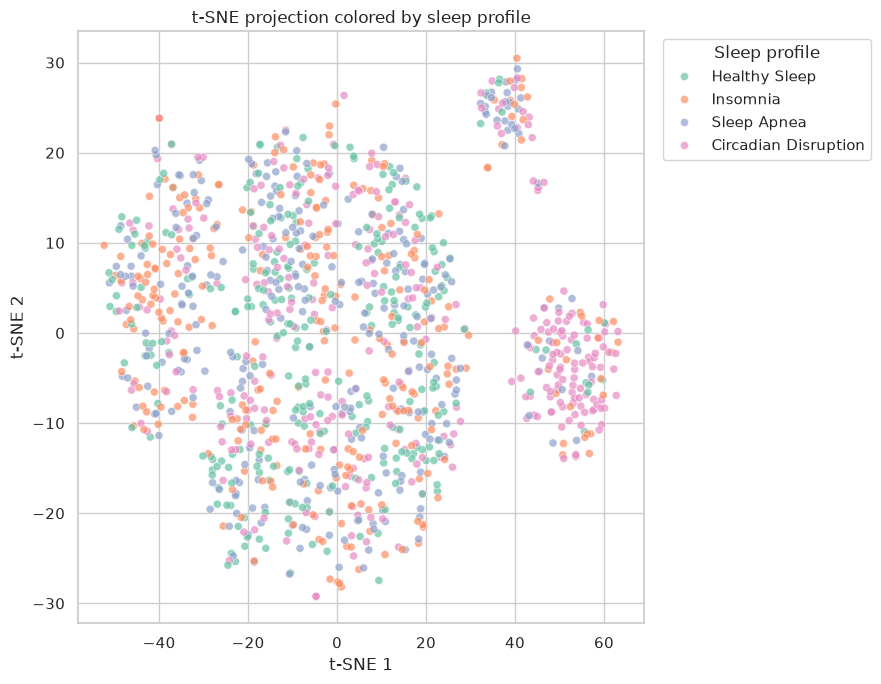

In [20]:
tsne = TSNE(
    n_components=2,
    perplexity=30,
    learning_rate="auto",
    init="pca",
    random_state=RANDOM_STATE,
)
X_tsne = tsne.fit_transform(X_scaled)

tsne_scores = pd.DataFrame(X_tsne, columns=["tSNE1", "tSNE2"])
tsne_scores["label_name"] = eda_df["label_name"].to_numpy()
tsne_scores.to_csv(TABLES_DIR / "tsne_scores.csv", index=False)

fig, ax = plt.subplots(figsize=(9, 7))
sns.scatterplot(
    data=tsne_scores,
    x="tSNE1",
    y="tSNE2",
    hue="label_name",
    hue_order=LABEL_ORDER,
    palette=CLASS_PALETTE,
    alpha=0.70,
    s=34,
    ax=ax,
)
ax.set(title="t-SNE projection colored by sleep profile", xlabel="t-SNE 1", ylabel="t-SNE 2")
ax.legend(title="Sleep profile", bbox_to_anchor=(1.02, 1), loc="upper left")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "13_tsne_by_class.png", dpi=180, bbox_inches="tight")
plt.show()


## 20. Optional UMAP

UMAP is another nonlinear projection that attempts to preserve local neighborhood structure while retaining more global organization than t-SNE in many datasets.

As with t-SNE, the visualization is exploratory. Apparent groups should not be converted directly into claims about classification performance.

If `umap-learn` is not installed, this section is skipped without affecting the rest of the notebook.


/home/david/miniconda3/envs/ml2026/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


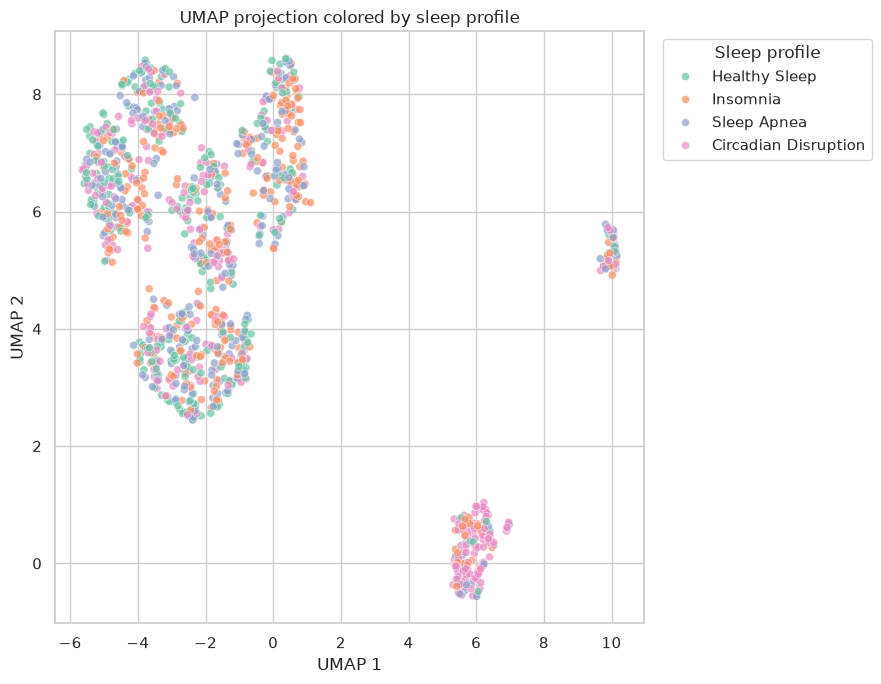

In [21]:
try:
    with warnings.catch_warnings():
        warnings.filterwarnings("ignore", message="IProgress not found.*")
        import umap.umap_ as umap
    UMAP_AVAILABLE = True
except ImportError:
    UMAP_AVAILABLE = False

if UMAP_AVAILABLE:
    reducer = umap.UMAP(
        n_components=2,
        n_neighbors=15,
        min_dist=0.1,
        metric="euclidean",
        random_state=RANDOM_STATE,
    )
    X_umap = reducer.fit_transform(X_scaled)

    umap_scores = pd.DataFrame(X_umap, columns=["UMAP1", "UMAP2"])
    umap_scores["label_name"] = eda_df["label_name"].to_numpy()
    umap_scores.to_csv(TABLES_DIR / "umap_scores.csv", index=False)

    fig, ax = plt.subplots(figsize=(9, 7))
    sns.scatterplot(
        data=umap_scores,
        x="UMAP1",
        y="UMAP2",
        hue="label_name",
        hue_order=LABEL_ORDER,
        palette=CLASS_PALETTE,
        alpha=0.70,
        s=34,
        ax=ax,
    )
    ax.set(title="UMAP projection colored by sleep profile", xlabel="UMAP 1", ylabel="UMAP 2")
    ax.legend(title="Sleep profile", bbox_to_anchor=(1.02, 1), loc="upper left")
    fig.tight_layout()
    fig.savefig(FIGURES_DIR / "14_umap_by_class.png", dpi=180, bbox_inches="tight")
    plt.show()
else:
    print("UMAP skipped: install 'umap-learn' to run this optional section.")


# Part VIII — Reproducible EDA summary

## 21. Export an execution summary

A compact JSON summary records what this EDA actually analyzed. This is useful for traceability and for later notebooks that need to know where the outputs came from.


In [22]:
eda_summary = {
    "dataset": "synthetic_sleep_profiles",
    "task_type": "multiclass_classification",
    "input_file": str(PROCESSED_DATA_PATH.relative_to(PROJECT_ROOT)),
    "target_column": TARGET_COLUMN,
    "target_classes": TARGET_CLASSES,
    "n_observations": int(len(df)),
    "n_numerical_features": int(len(NUMERICAL_COLUMNS)),
    "n_categorical_features": int(len(CATEGORICAL_COLUMNS)),
    "top_numerical_features_by_epsilon_squared": numerical_omnibus.head(5)["feature"].tolist(),
    "top_categorical_features_by_cramers_v": categorical_tests.head(5)["feature"].tolist(),
    "pca_pc1_variance_ratio": float(pca_2d.explained_variance_ratio_[0]),
    "pca_pc2_variance_ratio": float(pca_2d.explained_variance_ratio_[1]),
    "umap_executed": bool(UMAP_AVAILABLE),
}

with (RESULTS_DIR / "eda_summary.json").open("w", encoding="utf-8") as file:
    json.dump(eda_summary, file, indent=2)

print(json.dumps(eda_summary, indent=2))


{
  "dataset": "synthetic_sleep_profiles",
  "task_type": "multiclass_classification",
  "input_file": "data/synthetic_sleep_profiles/processed_data/synthetic_sleep_profiles_1200_processed.csv",
  "target_column": "sleep_profile",
  "target_classes": [
    "healthy_sleep",
    "insomnia",
    "sleep_apnea",
    "circadian_disruption"
  ],
  "n_observations": 1200,
  "n_numerical_features": 15,
  "n_categorical_features": 6,
  "top_numerical_features_by_epsilon_squared": [
    "sleep_latency_min",
    "sleep_efficiency_pct",
    "stress_score_0_10",
    "bedtime_variability_min",
    "social_jetlag_hours"
  ],
  "top_categorical_features_by_cramers_v": [
    "shift_worker",
    "anxiety_history",
    "loud_snoring",
    "sex_female",
    "evening_alcohol"
  ],
  "pca_pc1_variance_ratio": 0.12891316123998248,
  "pca_pc2_variance_ratio": 0.10859051257953027,
  "umap_executed": true
}


## 22. What this notebook does — and what it does not do

This EDA has described class composition, class-conditioned distributions, categorical prevalence, outlier patterns, multiclass statistical associations, pairwise follow-up contrasts, dependence structure, and low-dimensional geometry.

It has **not** established predictive performance. In particular:

- a small p-value is not a classifier;
- a large effect size is not an accuracy estimate;
- separation in PCA/t-SNE/UMAP is not a validated decision boundary;
- no feature should be selected for a predictive pipeline using the full dataset before train/test separation.

The next modelling stages must introduce data splitting and ensure that every learned transformation or feature-selection decision is estimated using training data only.
